[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/cops_and_robbers.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# Cops and robbers: who wins?

Economic Networks, Part 1  

Rules  
-----  
The cop picks a start node, then the robber picks one. They take turns  
(cop first). On a turn you move along one link or stay put. Both see  
everything. The cop wins by landing on the robber.  

This script answers, for ANY small network:  
1. who wins from given starting positions (and in how many moves),  
2. whether one cop can always win (and from which start),  
3. the corner test from the lecture (remove covered nodes one by one),  
4. how many cops are needed (the cop number),  
and draws pictures of the answer.  

The solver works backwards from every capture position ("retrograde  
analysis"), the same way chess endgames are solved, so its answers are  
exact, not simulations.  

The file is split into cells (# %%) so it runs piece by piece in VS Code,  
or you can paste each cell into Colab.

## Setup

In [1]:
%matplotlib inline

In [2]:
from itertools import product
import networkx as nx
import matplotlib.pyplot as plt

BLUE, CORAL, INK, MUTED, LINE = "#2D6CF6", "#F2464F", "#1B1F3B", "#8A8FA8", "#C9CCD8"


def closed_nbhd(G, v):
    """v plus its neighbours: everywhere you can be after one turn."""
    return set(G[v]) | {v}

## The solver

In [3]:
def solve(G, cops=1):
    """Solve the game exactly on network G with `cops` cops.

    Returns a dict mapping each state (cop_positions, robber, turn) to the
    number of cop moves still needed to catch the robber with best play.
    States missing from the dict are ones the robber can escape from forever.
    turn is 'cop' or 'robber' (whose move it is).
    """
    nodes = list(G)
    nb = {v: closed_nbhd(G, v) for v in nodes}
    cop_tuples = list(product(nodes, repeat=cops))
    caught = lambda cs, r: r in cs

    win = {}
    # Captured positions: zero moves left
    for cs in cop_tuples:
        for r in nodes:
            if caught(cs, r):
                win[(cs, r, "cop")] = 0
                win[(cs, r, "robber")] = 0

    changed = True
    while changed:
        changed = False
        for cs in cop_tuples:
            for r in nodes:
                # Cop to move: wins if SOME move leads to a winning state
                s = (cs, r, "cop")
                if s not in win:
                    best = None
                    for nxt in product(*(nb[c] for c in cs)):
                        if caught(nxt, r):
                            best = 1
                            break
                        t = win.get((nxt, r, "robber"))
                        if t is not None and (best is None or t + 1 < best):
                            best = t + 1
                    if best is not None:
                        win[s] = best
                        changed = True
                # Robber to move: cop wins only if EVERY robber move loses
                s = (cs, r, "robber")
                if s not in win:
                    times = [win.get((cs, r2, "cop")) for r2 in nb[r]]
                    if all(t is not None for t in times):
                        win[s] = max(times)
                        changed = True
    return win


def who_wins(G, cop_start, robber_start, first="cop", win=None):
    """Who wins from these starting positions?
    cop_start: a node (one cop) or a tuple of nodes (several cops)."""
    cs = cop_start if isinstance(cop_start, tuple) else (cop_start,)
    win = win or solve(G, cops=len(cs))
    t = win.get((cs, robber_start, first))
    if t is None:
        return "robber escapes forever"
    return f"cop wins in {t} move{'s' if t != 1 else ''}"


def cop_can_always_win(G, cops=1, win=None):
    """The real game: cops pick starts first, then the robber picks.
    Returns (True, best cop start, moves needed) or (False, None, None)."""
    win = win or solve(G, cops=cops)
    best = None
    for cs in product(list(G), repeat=cops):
        times = [win.get((cs, r, "cop")) for r in G if r not in cs]
        if times and all(t is not None for t in times):
            worst = max(times)
            if best is None or worst < best[1]:
                best = (cs, worst)
    if best is None:
        return False, None, None
    return True, best[0] if cops > 1 else best[0][0], best[1]


def cop_number(G, max_cops=3):
    """Smallest number of cops that can always win."""
    for k in range(1, max_cops + 1):
        if cop_can_always_win(G, cops=k)[0]:
            return k
    return f"more than {max_cops}"

## The corner test from the lecture

In [4]:
def corner_test(G, verbose=True):
    """Remove 'covered' nodes one at a time (a node is covered by a partner
    who is linked to all its other partners). One node left = cop wins."""
    H = G.copy()
    order = []
    while len(H) > 1:
        for u in sorted(H, key=str):
            cover = [v for v in H[u] if closed_nbhd(H, u) <= closed_nbhd(H, v)]
            if cover:
                order.append((u, cover[0]))
                H.remove_node(u)
                break
        else:
            if verbose:
                print("  stuck with", sorted(H, key=str), "-> robber wins")
            return False, order
    if verbose:
        for u, v in order:
            print(f"  {u} sits down (covered by {v})")
        print("  one node left -> cop wins")
    return True, order

## Playing out a game with best play on both sides

In [5]:
def play(G, cop_start, robber_start, first="cop", max_turns=10, win=None):
    """Positions turn by turn when both sides play well.
    The cop moves to catch as fast as possible (and, if it can't win,
    chases the robber anyway); a robber who will lose delays as long as
    possible; a robber who can escape stays safe."""
    win = win or solve(G)
    dist = dict(nx.all_pairs_shortest_path_length(G))
    c, r, turn = cop_start, robber_start, first
    history = [(c, r)]
    for _ in range(max_turns):
        if c == r:
            break
        if turn == "cop":
            options = closed_nbhd(G, c)
            def score(c2):
                if c2 == r:
                    return 0
                t = win.get(((c2,), r, "robber"))
                return t if t is not None else 100 + dist[c2][r]
            c = min(sorted(options, key=str), key=score)
            turn = "robber"
        else:
            options = closed_nbhd(G, r)
            def score(r2):
                t = win.get(((c,), r2, "cop"))
                return -1 if t is None else t      # escaping beats any delay
            r = max(sorted(options, key=str), key=lambda r2: (score(r2) == -1, score(r2)))
            turn = "cop"
        history.append((c, r))
    return history

## Pictures

In [6]:
def draw_outcomes(G, cop_start, pos=None, title=None, ax=None, win=None):
    """For a fixed cop start, colour every robber start:
    blue = cop wins (number = moves needed), coral = robber escapes."""
    win = win or solve(G)
    pos = pos or nx.spring_layout(G, seed=3)
    ax = ax or plt.gca()
    colors, labels = [], {}
    for v in G:
        if v == cop_start:
            colors.append(INK)
            labels[v] = "C"
            continue
        t = win.get(((cop_start,), v, "cop"))
        colors.append(BLUE if t is not None else CORAL)
        labels[v] = str(t) if t is not None else "R"
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=LINE, width=2.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=900,
                           edgecolors="white", linewidths=2)
    nx.draw_networkx_labels(G, pos, labels, ax=ax, font_color="white",
                            font_weight="bold")
    ax.set_title(title or f"Cop starts at {cop_start}", loc="left", fontsize=11)
    ax.axis("off")


def draw_game(G, history, pos=None, title="", path=None):
    """Small multiples: one panel per turn of a game with best play."""
    pos = pos or nx.spring_layout(G, seed=3)
    n = len(history)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.8))
    axes = [axes] if n == 1 else axes
    for i, (ax, (c, r)) in enumerate(zip(axes, history)):
        colors = [INK if v == c else CORAL if v == r else MUTED for v in G]
        if c == r:
            colors = [BLUE if v == c else MUTED for v in G]
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color=LINE, width=2)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=620,
                               edgecolors="white", linewidths=1.5)
        nx.draw_networkx_labels(G, pos, {v: str(v)[:1] for v in G}, ax=ax,
                                font_color="white", font_weight="bold", font_size=10)
        ax.set_title("start" if i == 0 else ("caught!" if c == r else f"move {i}"),
                     fontsize=10)
        ax.axis("off")
    fig.suptitle(title, x=0.02, ha="left", fontsize=11)
    fig.text(0.02, 0.01, "Dark = cop, coral = robber, blue = capture. Letters are first initials.",
             fontsize=9, color=INK)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    if path:
        fig.savefig(path, dpi=160)
    return fig

## Example networks from the lecture

In [7]:
def lecture_networks():
    square = nx.cycle_graph(["Ana", "Ben", "Carla", "David"])
    diagonal = square.copy()
    diagonal.add_edge("Ben", "David")
    house = square.copy()
    house.add_edges_from([("Elena", "Ana"), ("Elena", "Ben")])
    house_diag = house.copy()
    house_diag.add_edge("Ben", "David")
    return {
        "Square (Round 1)": square,
        "Square + diagonal (Round 2)": diagonal,
        "House (Round 3)": house,
        "House + diagonal": house_diag,
        "Tree (org chart)": nx.balanced_tree(2, 2),
        "3 x 3 grid": nx.grid_2d_graph(3, 3),
        "Petersen graph": nx.petersen_graph(),
    }


SQUARE_POS = {"Ana": (0, 1), "Ben": (1, 1), "Carla": (1, 0), "David": (0, 0), "Elena": (0.5, 1.6)}

## Run everything

In [8]:
print("One cop can always win?   (and the cop number)")
for name, G in lecture_networks().items():
    ok, start, moves = cop_can_always_win(G)
    extra = f"start at {start}, catch within {moves} move{'s' if moves != 1 else ''}" if ok else ""
    print(f"  {name:28s} {'yes' if ok else 'no ':3s}  cops needed: {cop_number(G)}  {extra}")

nets = lecture_networks()
print("\nCorner test, square + diagonal:")
corner_test(nets["Square + diagonal (Round 2)"])
print("Corner test, house:")
corner_test(nets["House (Round 3)"])

print("\nStarting conditions matter (square):")
sq = nets["Square (Round 1)"]
for c0, r0, first in [("Ana", "Carla", "cop"), ("Ana", "Ben", "cop"),
                      ("Ana", "Ben", "robber")]:
    print(f"  cop {c0}, robber {r0}, {first} moves first: {who_wins(sq, c0, r0, first)}")

print("\nTwo cops on the square:", who_wins(sq, ("Ana", "Carla"), "Ben"))

One cop can always win?   (and the cop number)
  Square (Round 1)             no   cops needed: 2  
  Square + diagonal (Round 2)  yes  cops needed: 1  start at Ben, catch within 1 move
  House (Round 3)              no   cops needed: 2  
  House + diagonal             yes  cops needed: 1  start at Ben, catch within 1 move
  Tree (org chart)             yes  cops needed: 1  start at 0, catch within 2 moves
  3 x 3 grid                   no   cops needed: 2  


  Petersen graph               no   cops needed: 3  

Corner test, square + diagonal:
  Ana sits down (covered by Ben)
  Ben sits down (covered by Carla)
  Carla sits down (covered by David)
  one node left -> cop wins
Corner test, house:
  stuck with ['Ana', 'Ben', 'Carla', 'David'] -> robber wins

Starting conditions matter (square):
  cop Ana, robber Carla, cop moves first: robber escapes forever
  cop Ana, robber Ben, cop moves first: cop wins in 1 move
  cop Ana, robber Ben, robber moves first: robber escapes forever

Two cops on the square: cop wins in 1 move


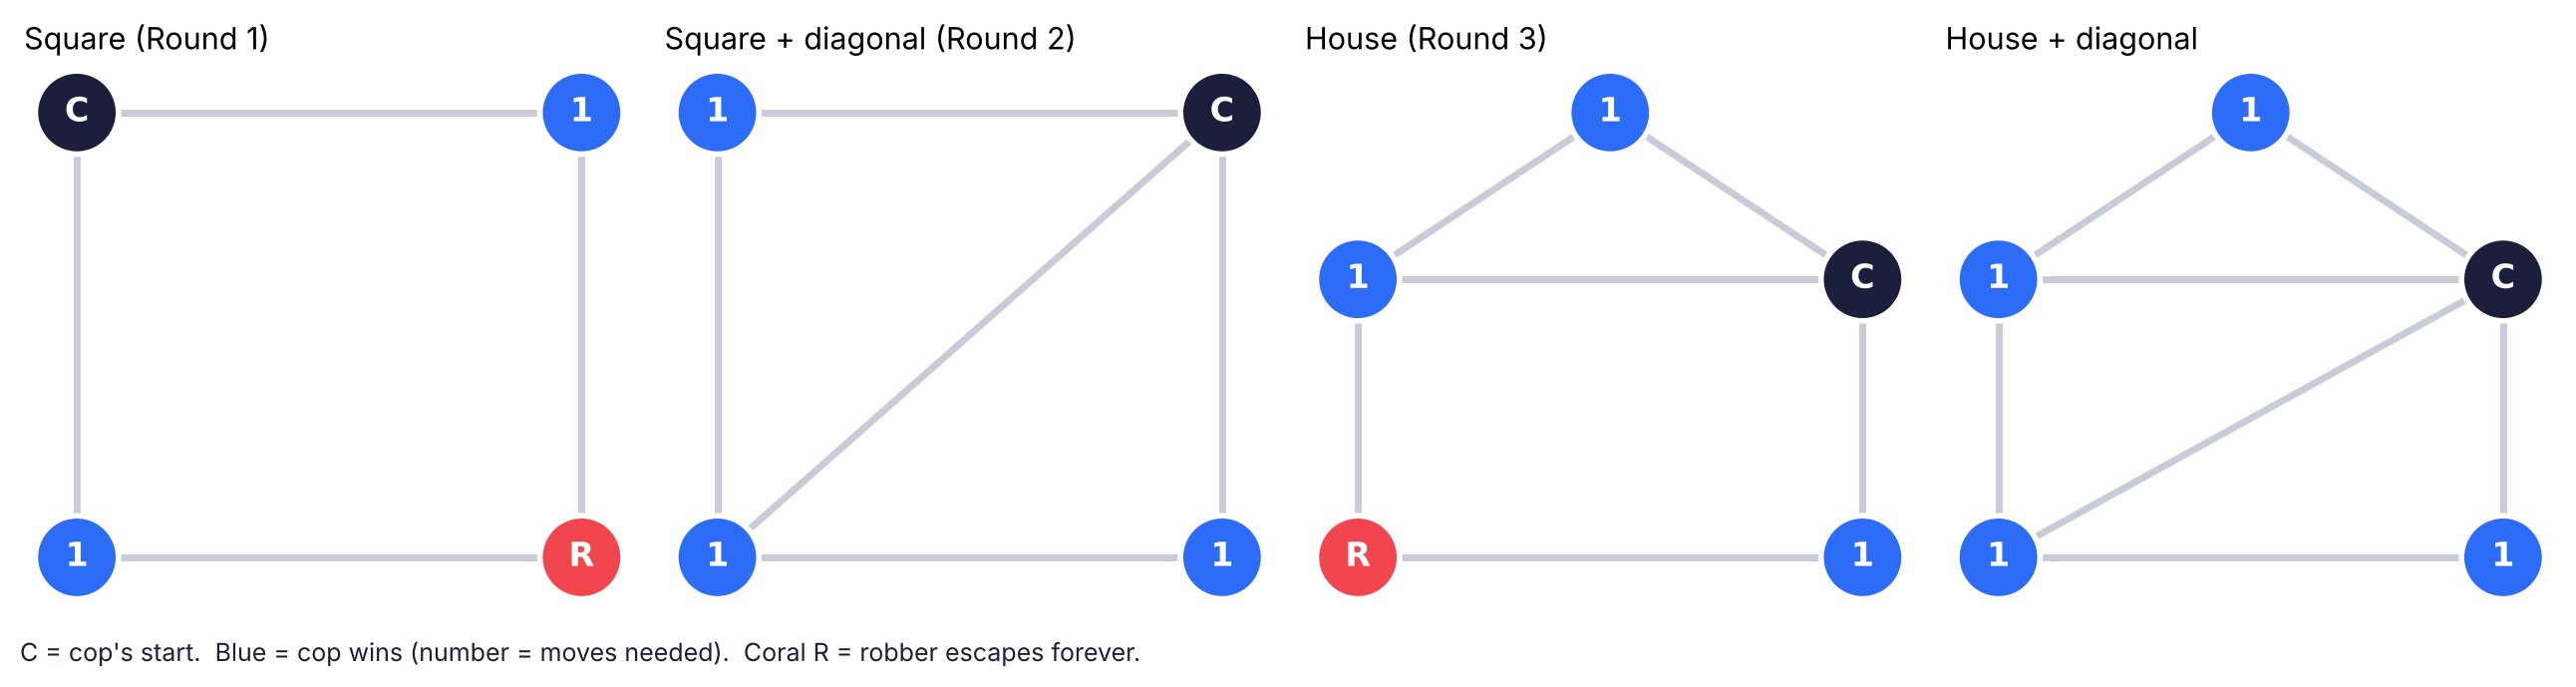

In [9]:
# Figure 1: outcomes for every robber start, four lecture networks
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (name, start) in zip(axes, [("Square (Round 1)", "Ana"),
                                    ("Square + diagonal (Round 2)", "Ben"),
                                    ("House (Round 3)", "Ben"),
                                    ("House + diagonal", "Ben")]):
    draw_outcomes(nets[name], start, pos=SQUARE_POS, title=name, ax=ax)
fig.text(0.01, 0.01, "C = cop's start.  Blue = cop wins (number = moves needed).  "
         "Coral R = robber escapes forever.", fontsize=9, color=INK)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("cr_fig1_who_wins.png", dpi=160)


Saved cr_fig1_who_wins.png, cr_fig2_diagonal_game.png, cr_fig3_square_game.png


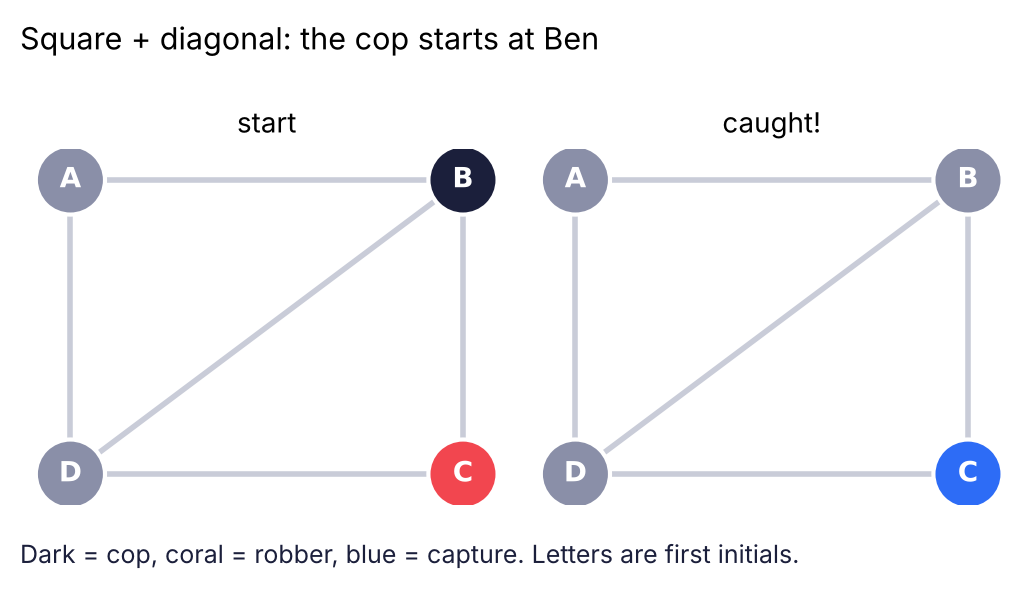

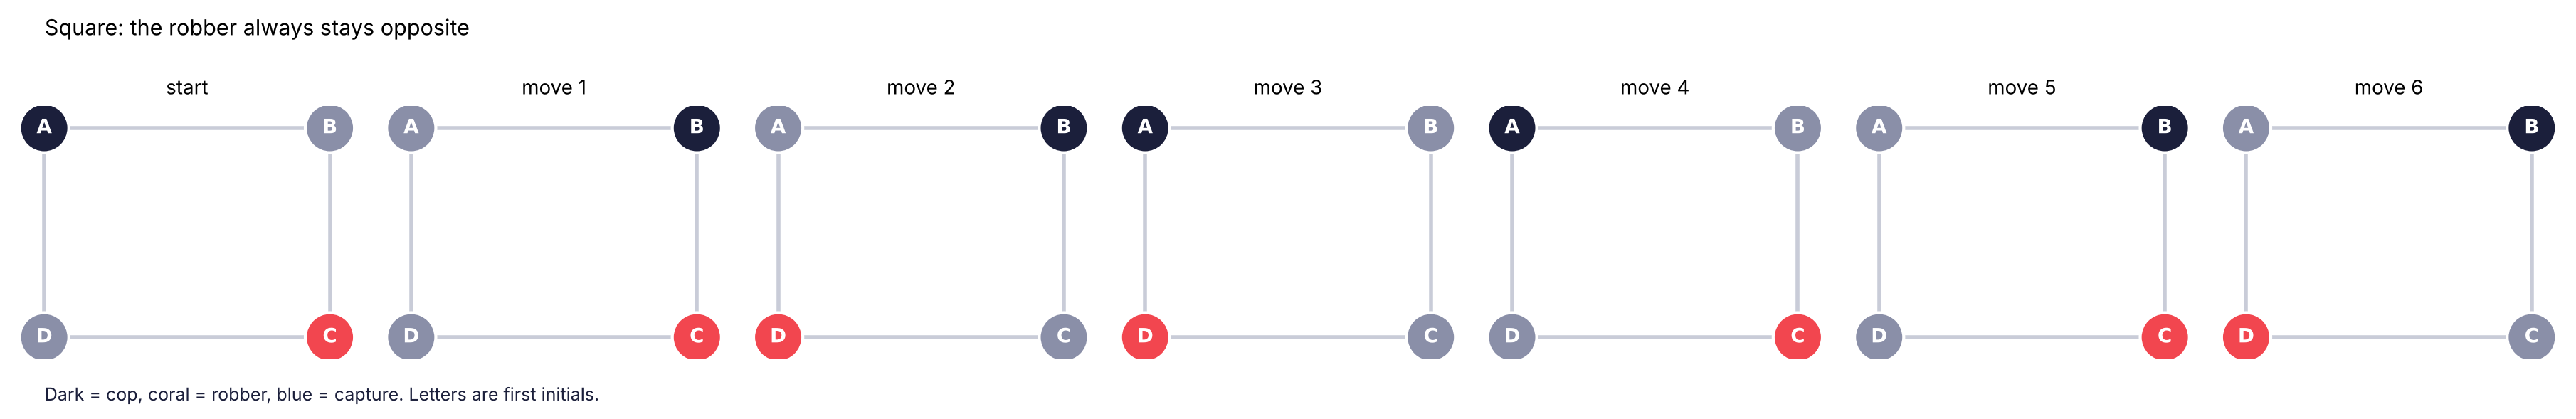

In [10]:
# Figure 2: a game played out with best play on both sides
draw_game(nets["Square + diagonal (Round 2)"],
          play(nets["Square + diagonal (Round 2)"], "Ben", "Carla"),
          pos=SQUARE_POS, title="Square + diagonal: the cop starts at Ben",
          path="cr_fig2_diagonal_game.png")
draw_game(sq, play(sq, "Ana", "Carla", max_turns=6), pos=SQUARE_POS,
          title="Square: the robber always stays opposite",
          path="cr_fig3_square_game.png")
print("\nSaved cr_fig1_who_wins.png, cr_fig2_diagonal_game.png, cr_fig3_square_game.png")